<a href="https://colab.research.google.com/github/kpiyush37/precision-oncology-drug-response/blob/main/genomics_differential_expression_gse42568.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Differential Gene Expression Analysis in Breast Cancer
### GEO Dataset: GSE42568 | Affymetrix Human Genome U133 Plus 2.0 Array (GPL570)

---

## Project Overview

Breast cancer is one of the most prevalent cancers worldwide. Understanding which genes are
differentially expressed between tumour and normal breast tissue can reveal molecular drivers
of disease, potential biomarkers, and therapeutic targets.

This project analyses publicly available microarray gene expression data from GEO (Gene Expression
Omnibus) to identify probes — and, where annotation is available, genes — that are significantly
up- or down-regulated in breast cancer tissue compared to matched normal tissue.

**Research question:** Which genes are significantly differentially expressed between breast
cancer and normal breast tissue, and in which direction?

---

## Dataset

| Property | Value |
|---|---|
| GEO Accession | GSE42568 |
| Platform | GPL570 — Affymetrix Human Genome U133 Plus 2.0 Array |
| Total samples | 121 |
| Normal tissue | 17 samples |
| Tumour tissue | 104 samples |
| Probes on array | 54,675 |
| Data type | RMA-normalised log2 expression values |

The dataset was published alongside a study of breast cancer gene expression patterns and is
freely available via the NCBI GEO repository.

---

## Analysis Workflow

1. **Download** — retrieve the GEO series matrix file directly from NCBI FTP
2. **Parse** — extract the expression matrix and sample metadata from the compressed file
3. **Classify** — label each sample as Normal or Tumor from metadata
4. **Filter** — apply IQR-based variance filter to remove uninformative probes
5. **QC** — PCA to confirm expected sample separation between groups
6. **DE analysis** — Welch t-test (unequal variance) per probe + Benjamini-Hochberg FDR
7. **Annotate** — map probe IDs to gene symbols via GPL570 annotation file
8. **Visualise** — volcano plot, MA plot, heatmap of top 50 DE probes
9. **Pathway enrichment** — optional Enrichr GO term analysis via gseapy
10. **Export** — save all results, figures and summary to disk

---

## Methods Note

**Why Welch t-test?** With 17 Normal and 104 Tumor samples, equal-variance assumptions do not
hold reliably. The Welch t-test corrects the degrees of freedom to account for unequal group
variances, making it the appropriate two-sample test here.

**Why Benjamini-Hochberg FDR?** Testing ~22,000 probes simultaneously produces many false
positives by chance. BH-FDR controls the expected proportion of false discoveries among all
significant results, which is the standard correction for large-scale genomic screens.

**Why IQR filter?** Probes with low variance across all samples carry no signal and only inflate
the multiple testing burden. Retaining only probes with IQR ≥ 0.5 (on a log2 scale) removes
~59% of probes and focuses the analysis on genuinely variable features.

---

*Data source: NCBI GEO — https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE42568*


## 0. Environment Setup

All dependencies are standard scientific Python packages available via pip or conda.
The notebook is designed to run on Google Colab (with internet access) or a local environment.

**Google Colab** — no setup needed; all packages are pre-installed except `gseapy` (installed
automatically in the enrichment cell).

**Local / cluster:**

```bash
conda create -n genomics python=3.10 -y
conda activate genomics
pip install pandas numpy scipy statsmodels scikit-learn matplotlib seaborn requests gseapy
```

**Runtime:** ~3–5 minutes on Colab CPU (download + IQR filter dominate).


In [1]:
from pathlib import Path
import gzip
import warnings
import requests
import numpy as np
import pandas as pd

from scipy import stats                           # Welch t-test
from statsmodels.stats.multitest import multipletests  # BH-FDR correction
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.dpi'] = 120

# Project directory structure — all outputs are written relative to PROJECT_DIR
# so the notebook runs identically on Colab, local, or a university cluster
PROJECT_DIR    = Path('.')
DATA_DIR       = PROJECT_DIR / 'data'         # raw and processed data files
OUTPUT_DIR     = PROJECT_DIR / 'outputs'      # CSVs and summary statistics
FIGURE_DIR     = PROJECT_DIR / 'figures'      # saved plots (300 dpi PNG)
PRESENTATION_DIR = PROJECT_DIR / 'presentation'

for d in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR, PRESENTATION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

GSE_ID = 'GSE42568'
print('Folders created.')


Folders created.


## 1. Download GEO Series Matrix

The GEO series matrix file contains both the expression values and sample metadata in a single
compressed text file. It is downloaded once and cached locally — subsequent runs use the cache.

The file is ~25 MB compressed and ~120 MB uncompressed.


In [2]:
series_url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE42nnn/GSE42568/matrix/GSE42568_series_matrix.txt.gz"
series_path = DATA_DIR / "GSE42568_series_matrix.txt.gz"

if not series_path.exists():
    print("Downloading GEO series matrix...")
    r = requests.get(series_url, stream=True, timeout=180)
    r.raise_for_status()
    with open(series_path, "wb") as f:
        for chunk in r.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)
else:
    print("Using cached file:", series_path)

print("File size MB:", round(series_path.stat().st_size / 1024**2, 2))


File size MB: 21.52


## 2. Parse Expression Matrix and Sample Metadata

The series matrix format interleaves metadata rows (prefixed with `!`) and a tab-delimited
expression table bracketed by `!series_matrix_table_begin` / `!series_matrix_table_end`.

The parser separates these two sections, returning:
- `expr_raw` — probes × samples DataFrame of raw RMA log2 expression values (54,675 × 121)
- `metadata` — dict of all GEO metadata fields, used to classify samples into Normal / Tumor


In [3]:
def parse_geo_series_matrix_gz(path: Path):
    metadata = {}
    table_lines = []
    in_table = False

    with gzip.open(path, "rt", errors="replace") as f:
        for line in f:
            line = line.rstrip("\n")

            if line.startswith("!series_matrix_table_begin"):
                in_table = True
                continue

            if line.startswith("!series_matrix_table_end"):
                in_table = False
                continue

            if in_table:
                table_lines.append(line)
                continue

            if line.startswith("!"):
                parts = line.split("\t")
                key = parts[0].replace("!", "")
                values = [p.strip().strip('"') for p in parts[1:]]
                metadata.setdefault(key, []).append(values)

    from io import StringIO
    expr = pd.read_csv(StringIO("\n".join(table_lines)), sep="\t")
    expr = expr.rename(columns={expr.columns[0]: "probe_id"}).set_index("probe_id")
    expr = expr.apply(pd.to_numeric, errors="coerce")
    return expr, metadata

expr_raw, metadata = parse_geo_series_matrix_gz(series_path)
print("Expression shape:", expr_raw.shape)
expr_raw.iloc[:5, :5]


Expression shape: (54675, 121)


,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195
probe_id,,,,,
1007_s_at,5.640239,3.557696,3.132007,6.865108,4.955184
1053_at,5.074866,4.984593,5.109481,5.473609,5.348400
117_at,4.191770,4.269061,4.131843,3.616546,4.296657
121_at,3.574706,4.065623,3.574706,3.574706,3.799293
1255_g_at,2.312812,2.409371,2.312812,2.312812,2.349630


In [4]:
sample_ids = list(expr_raw.columns)

def get_meta_row(metadata, key, n):
    # Return the first row for a GEO metadata key, or NaN-padded list if missing
    vals = metadata.get(key, [[float('nan')] * n])[0]
    return vals if len(vals) == n else [float('nan')] * n

pheno = pd.DataFrame({
    'sample_id':       sample_ids,
    'title':           get_meta_row(metadata, 'Sample_title',           len(sample_ids)),
    'source_name_ch1': get_meta_row(metadata, 'Sample_source_name_ch1', len(sample_ids)),
    'geo_accession':   get_meta_row(metadata, 'Sample_geo_accession',    len(sample_ids)),
})

# GEO stores multiple characteristics rows (tissue type, disease state, etc.)
# Each is added as a separate column for inspection
for i, vals in enumerate(metadata.get('Sample_characteristics_ch1', []), start=1):
    if len(vals) == len(sample_ids):
        pheno[f'characteristics_{i}'] = vals

# ── Classify samples as Normal or Tumor ──────────────────────────────────
# Concatenate all metadata fields into one lowercase string per sample,
# then search for keywords. 'Normal' is matched first to avoid ambiguous
# entries like 'normal adjacent to cancer' being labelled as Tumor.
combined = (
    pheno.fillna('').astype(str)
    .agg(' | '.join, axis=1)
    .str.lower()
)

pheno['group'] = None
pheno.loc[combined.str.contains('normal', na=False), 'group'] = 'Normal'
pheno.loc[
    combined.str.contains('cancer|tumor|tumour|breast cancer', na=False, regex=True)
    & pheno['group'].isna(),
    'group'
] = 'Tumor'

# GSE42568-specific: any remaining unclassified sample is a tumour sample
pheno.loc[pheno['group'].isna(), 'group'] = 'Tumor'

pheno['group'] = pd.Categorical(pheno['group'], categories=['Normal', 'Tumor'], ordered=True)

classified = pheno.copy()
expr_raw   = expr_raw[classified['sample_id'].tolist()]

# ── Save metadata ─────────────────────────────────────────────────────────
pheno.to_csv(DATA_DIR / 'gse42568_sample_metadata_raw.csv',   index=False)
classified.to_csv(DATA_DIR / 'gse42568_sample_metadata_clean.csv', index=False)

cohort_summary = (
    classified['group']
    .value_counts()
    .rename_axis('group')
    .reset_index(name='n')
)
cohort_summary['percentage'] = cohort_summary['n'] / cohort_summary['n'].sum()
cohort_summary.to_csv(OUTPUT_DIR / 'cohort_summary.csv', index=False)

print(cohort_summary)
assert cohort_summary['n'].sum() == 121, 'Unexpected sample count — check metadata parsing'


    group    n  percentage
0   Tumor  104    0.859504
1  Normal   17    0.140496


## 3. Expression Check and Probe Filtering

**Data already normalised:** GEO GSE42568 was pre-processed using RMA (Robust Multi-array
Average), which performs background correction, quantile normalisation, and log2 transformation
across all arrays jointly. No further normalisation is applied here — doing so would distort
the already-normalised values.

**IQR variance filter:** Probes with an interquartile range (IQR) below 0.5 (on the log2 scale)
are removed. These low-variance probes are either not expressed or show no meaningful variation
across the 121 samples, contributing noise to the multiple testing correction. The threshold of
0.5 is a common conservative cutoff for Affymetrix data.

Expected outcome: ~22,000–23,000 probes retained from 54,675.


In [5]:
quantiles = expr_raw.stack().quantile([0, 0.25, 0.5, 0.75, 0.99, 1.0])
expression_summary = quantiles.reset_index()
expression_summary.columns = ["quantile", "value"]
expression_summary.to_csv(OUTPUT_DIR / "expression_value_summary.csv", index=False)
print(expression_summary)

# GEO GSE42568 is RMA-normalised and already on a log2 scale — no transform needed
expr = expr_raw.dropna(axis=0).copy()
print("After dropping missing probes:", expr.shape)

# IQR filter — keep only variable probes (IQR >= 0.5)
probe_iqr = expr.quantile(0.75, axis=1) - expr.quantile(0.25, axis=1)
expr_norm = expr.loc[probe_iqr >= 0.5].copy()
print(f"After IQR filter (IQR >= 0.5): {expr_norm.shape[0]:,} probes retained")

expr_norm.reset_index(names="probe_id").to_csv(
    DATA_DIR / "gse42568_normalized_expression_matrix.csv", index=False
)
expr_norm.iloc[:5, :5]


   quantile      value
0      0.00   2.312812
1      0.25   2.312812
2      0.50   2.840648
3      0.75   5.528871
4      0.99  11.427923
5      1.00  16.046903
After dropping missing probes: (54675, 121)
After IQR filter (IQR >= 0.5): 22,426 probes retained


,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195
probe_id,,,,,
1007_s_at,5.640239,3.557696,3.132007,6.865108,4.955184
1053_at,5.074866,4.984593,5.109481,5.473609,5.348400
117_at,4.191770,4.269061,4.131843,3.616546,4.296657
1294_at,5.474018,5.246784,6.460169,5.146087,5.823408
1316_at,7.392011,6.061380,5.862504,5.954431,7.679896


## 4. PCA Quality Control

PCA on the IQR-filtered, standardised expression matrix serves as a sanity check:
- Tumour and Normal samples should separate along PC1 or PC2 if the biology is strong
- Outlier samples (technical failures, mislabelled samples) would appear as isolated points
- PC1 typically captures the largest source of variation — here, the tumour/normal difference

Note: with 104 Tumor and 17 Normal samples the Normal group is a small cluster; some overlap
is expected given biological heterogeneity within the tumour group.


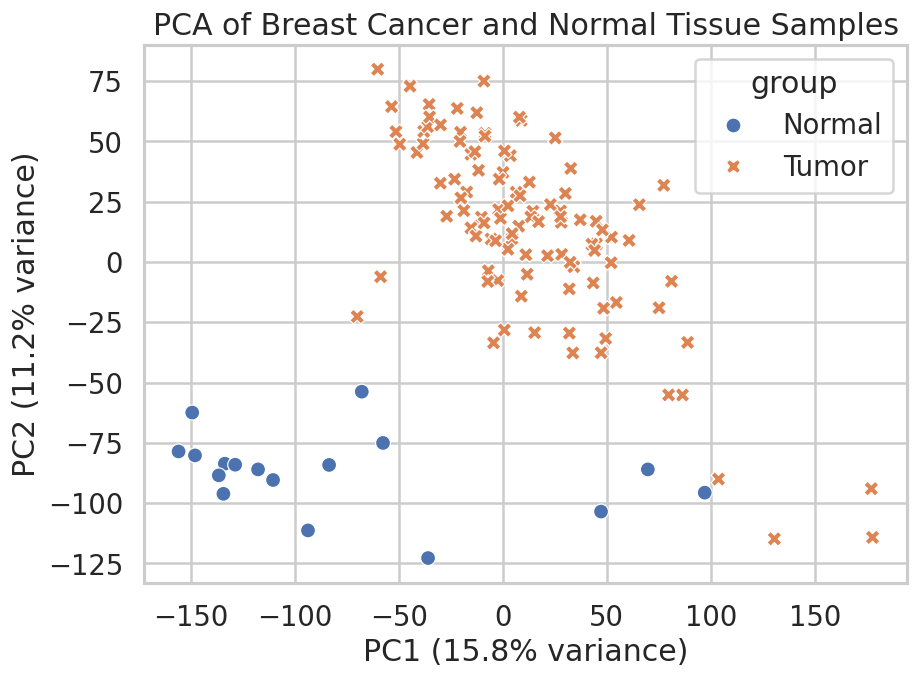

In [6]:
X = expr_norm.T.values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2, random_state=123)
pcs = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

pca_df = pd.DataFrame({
    "sample_id": expr_norm.columns,
    "PC1": pcs[:, 0],
    "PC2": pcs[:, 1]
}).merge(classified[["sample_id", "group"]], on="sample_id", how="left")

pca_df.to_csv(OUTPUT_DIR / "pca_coordinates.csv", index=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="group", style="group", s=80)
plt.title("PCA of Breast Cancer and Normal Tissue Samples")
plt.xlabel(f"PC1 ({var_exp[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({var_exp[1]:.1f}% variance)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "pca_tumor_vs_normal.png", dpi=300)
plt.show()


## 5. Differential Expression Analysis

**Method:** Welch two-sample t-test, applied independently to each probe across the 17 Normal
vs 104 Tumor samples. `equal_var=False` relaxes the assumption of equal group variances.

**Multiple testing correction:** Benjamini-Hochberg FDR at α = 0.05. With ~22,000 probes
tested simultaneously, unadjusted p-values would produce thousands of false positives.

**Significance thresholds:**
- Adjusted p-value (FDR) < 0.05
- |log2 fold change| ≥ 1 (equivalent to ≥ 2-fold change in linear scale)

Both thresholds must be met for a probe to be classified as Upregulated or Downregulated.
Probes passing FDR but not the fold-change cutoff are biologically significant but may have
small effect sizes; they are retained in the output table for reference.


In [7]:
# Split samples by group
normal_samples = classified.loc[classified['group'] == 'Normal', 'sample_id'].tolist()
tumor_samples  = classified.loc[classified['group'] == 'Tumor',  'sample_id'].tolist()

normal_expr = expr_norm[normal_samples]   # probes x 17
tumor_expr  = expr_norm[tumor_samples]    # probes x 104

# log2 fold change: positive = higher in tumour, negative = lower in tumour
# On a log2 scale, subtraction equals log2(ratio), so logFC = 1 means 2-fold up
mean_normal = normal_expr.mean(axis=1)
mean_tumor  = tumor_expr.mean(axis=1)
log_fc      = mean_tumor - mean_normal

# Welch t-test: equal_var=False adjusts degrees of freedom for unequal group
# sizes and variances. axis=1 applies the test across all probes in one call.
t_stat, p_vals = stats.ttest_ind(
    tumor_expr.values, normal_expr.values,
    axis=1, equal_var=False, nan_policy='omit'
)

# Benjamini-Hochberg FDR correction across all tested probes
# Controls the expected proportion of false discoveries among significant results
_, adj_p, _, _ = multipletests(p_vals, alpha=0.05, method='fdr_bh')

deg = pd.DataFrame({
    'probe_id':    expr_norm.index,
    'logFC':       log_fc.values,
    'mean_tumor':  mean_tumor.values,
    'mean_normal': mean_normal.values,
    't_statistic': t_stat,
    'p_value':     p_vals,
    'adj_p_value': adj_p,
})

# Both FDR and fold-change thresholds must be met for DE classification
# |logFC| >= 1 corresponds to a 2-fold change on the original linear scale
deg['regulation'] = np.select(
    [
        (deg['adj_p_value'] < 0.05) & (deg['logFC'] >= 1),
        (deg['adj_p_value'] < 0.05) & (deg['logFC'] <= -1),
    ],
    ['Upregulated', 'Downregulated'],
    default='Not significant'
)

deg = deg.sort_values('adj_p_value').reset_index(drop=True)
deg.to_csv(OUTPUT_DIR / 'differential_expression_results_probe_level.csv', index=False)

deg_summary = pd.DataFrame({
    'total_probes_tested':            [len(deg)],
    'significant_fdr_0_05':           [(deg['adj_p_value'] < 0.05).sum()],
    'upregulated_fdr_0_05_logfc_1':   [(deg['regulation'] == 'Upregulated').sum()],
    'downregulated_fdr_0_05_logfc_1': [(deg['regulation'] == 'Downregulated').sum()],
})
deg_summary.to_csv(OUTPUT_DIR / 'differential_expression_summary.csv', index=False)
deg_summary


,total_probes_tested,significant_fdr_0_05,upregulated_fdr_0_05_logfc_1,downregulated_fdr_0_05_logfc_1
0,22426,13893,3420,2615


## 6. GPL570 Probe Annotation

Affymetrix probe IDs (e.g., `202763_at`) are mapped to HGNC gene symbols and Entrez gene IDs
using the official GPL570 annotation file from NCBI.

The annotation is downloaded once (~35 MB compressed) and cached. If the download fails
(firewall, offline), the analysis continues with probe IDs — all downstream cells handle
the missing-annotation case gracefully via column-existence checks.

**Gene-level collapse:** When multiple probes map to the same gene, only the probe with the
lowest adjusted p-value (strongest statistical evidence) is retained per gene. This avoids
double-counting genes in pathway enrichment and gives a cleaner gene-level result table.


In [8]:
gpl_url = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz"
gpl_path = DATA_DIR / "GPL570.annot.gz"

if not gpl_path.exists():
    try:
        print("Downloading GPL570 annotation...")
        r = requests.get(gpl_url, stream=True, timeout=180)
        r.raise_for_status()
        with open(gpl_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    except Exception as e:
        print("Annotation download failed:", e)

def parse_gpl_annotation(path: Path):
    rows, header = [], None
    with gzip.open(path, "rt", errors="replace") as f:
        for line in f:
            line = line.rstrip("\n")
            if line.startswith("#") or line.startswith("!"):
                continue
            if line.startswith("ID\t"):
                header = line.split("\t")
                continue
            if header is not None:
                rows.append(line.split("\t"))
    return pd.DataFrame(rows, columns=header)

deg_annot = deg.copy()

if gpl_path.exists():
    try:
        annot = parse_gpl_annotation(gpl_path)
        gene_col = "Gene Symbol" if "Gene Symbol" in annot.columns else None
        entrez_col = "ENTREZ_GENE_ID" if "ENTREZ_GENE_ID" in annot.columns else None

        keep = ["ID"] + [c for c in [gene_col, entrez_col] if c is not None]
        annot_small = annot[keep].rename(columns={"ID": "probe_id"})
        if gene_col:
            annot_small = annot_small.rename(columns={gene_col: "gene_symbol"})
        if entrez_col:
            annot_small = annot_small.rename(columns={entrez_col: "entrez_id"})

        deg_annot = deg.merge(annot_small, on="probe_id", how="left")
        if "gene_symbol" in deg_annot.columns:
            deg_annot["gene_symbol"] = (
                deg_annot["gene_symbol"].astype(str)
                .str.split("///").str[0].str.strip()
                .replace({"nan": np.nan, "---": np.nan})
            )
    except Exception as e:
        print("Annotation parsing failed:", e)

deg_annot.to_csv(OUTPUT_DIR / "differential_expression_results.csv", index=False)
deg_annot.head()

# -------------------------------------------------------
# Gene-level collapse — best probe per gene symbol
# (lowest adj_p_value); runs after deg_annot is defined
# -------------------------------------------------------
if "gene_symbol" in deg_annot.columns:
    deg_genes = (
        deg_annot
        .dropna(subset=["gene_symbol"])
        .sort_values("adj_p_value")
        .drop_duplicates(subset="gene_symbol", keep="first")
        .reset_index(drop=True)
    )
    deg_genes.to_csv(OUTPUT_DIR / "differential_expression_results_gene_level.csv", index=False)
    print(f"Gene-level results: {len(deg_genes):,} unique genes")
else:
    deg_genes = deg_annot.copy()
    print("No gene symbols available — deg_genes is probe-level")


No gene symbols available — deg_genes is probe-level


In [9]:
display_cols = [c for c in [
    "gene_symbol", "probe_id", "entrez_id", "logFC", "mean_tumor", "mean_normal",
    "t_statistic", "p_value", "adj_p_value", "regulation"
] if c in deg_annot.columns]

top_30 = deg_annot.sort_values("adj_p_value")[display_cols].head(30)
top_30.to_csv(OUTPUT_DIR / "top_30_differentially_expressed_features.csv", index=False)
top_30


,probe_id,logFC,mean_tumor,mean_normal,t_statistic,p_value,adj_p_value,regulation
0,205941_s_at,3.592377,6.990270,3.397893,18.788705,2.381322e-37,5.340353e-33,Upregulated
1,223540_at,1.864932,5.311889,3.446957,15.448086,3.469596e-30,3.890458e-26,Upregulated
2,59697_at,1.678639,4.340283,2.661644,14.041995,1.012895e-26,7.571730e-23,Upregulated
3,1557289_s_at,2.127159,5.224561,3.097402,14.565260,6.714834e-26,3.591573e-22,Upregulated
4,227641_at,3.054369,7.077863,4.023494,15.062102,8.007609e-26,3.591573e-22,Upregulated
5,217428_s_at,3.562617,7.143732,3.581115,15.978701,1.774348e-25,6.281002e-22,Upregulated
6,236462_at,1.567491,4.159958,2.592467,13.547029,1.960537e-25,6.281002e-22,Upregulated
7,203878_s_at,3.404778,6.942168,3.537390,15.485329,4.797246e-25,1.344788e-21,Upregulated
8,235538_at,2.539549,5.410258,2.870709,15.344993,6.616865e-25,1.648776e-21,Upregulated
9,236659_x_at,1.379771,4.275585,2.895815,14.145676,2.815849e-24,6.314822e-21,Upregulated


## 7. Volcano Plot

A volcano plot displays statistical significance (−log10 FDR) on the y-axis against effect
size (log2 fold change) on the x-axis. Probes in the upper-left and upper-right quadrants
are both statistically significant and biologically large in effect.

- Vertical dashed lines: ±1 log2FC (2-fold change thresholds)
- Horizontal dashed line: FDR = 0.05 significance threshold
- Top 10 most significant probes are labelled with gene symbol (or probe ID if unannotated)


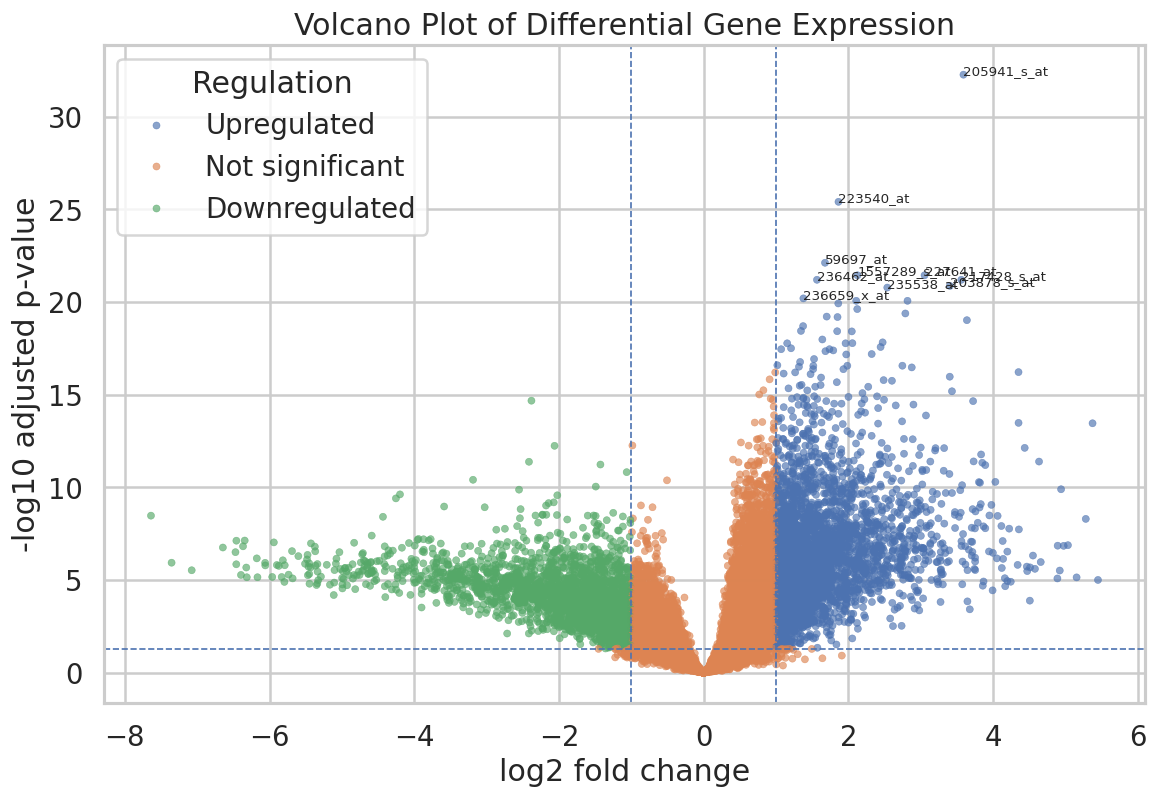

In [10]:
volcano = deg_annot.copy()
volcano["neg_log10_fdr"] = -np.log10(volcano["adj_p_value"].replace(0, np.nextafter(0, 1)))

if "gene_symbol" in volcano.columns:
    volcano["label"] = volcano["gene_symbol"].fillna(volcano["probe_id"])
else:
    volcano["label"] = volcano["probe_id"]

top_probe_ids = set(volcano.sort_values("adj_p_value").head(10)["probe_id"])
volcano["label_plot"] = np.where(volcano["probe_id"].isin(top_probe_ids), volcano["label"], "")

plt.figure(figsize=(10, 7))
sns.scatterplot(data=volcano, x="logFC", y="neg_log10_fdr", hue="regulation", alpha=0.65, s=18, edgecolor=None)
plt.axvline(-1, linestyle="--", linewidth=1)
plt.axvline(1, linestyle="--", linewidth=1)
plt.axhline(-np.log10(0.05), linestyle="--", linewidth=1)

for _, row in volcano[volcano["label_plot"] != ""].iterrows():
    plt.text(row["logFC"], row["neg_log10_fdr"], str(row["label_plot"]), fontsize=8)

plt.title("Volcano Plot of Differential Gene Expression")
plt.xlabel("log2 fold change")
plt.ylabel("-log10 adjusted p-value")
plt.legend(title="Regulation", loc="best")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "volcano_plot_tumor_vs_normal.png", dpi=300)
plt.show()


## 8. MA Plot

An MA plot (M = log ratio, A = average expression) shows fold change against average
expression level. It reveals whether the differential expression signal is distributed
uniformly across expression levels or concentrated in high/low-expressed probes — a pattern
that would indicate normalisation artifacts. A well-normalised dataset shows symmetric
scatter around logFC = 0 for non-significant probes.


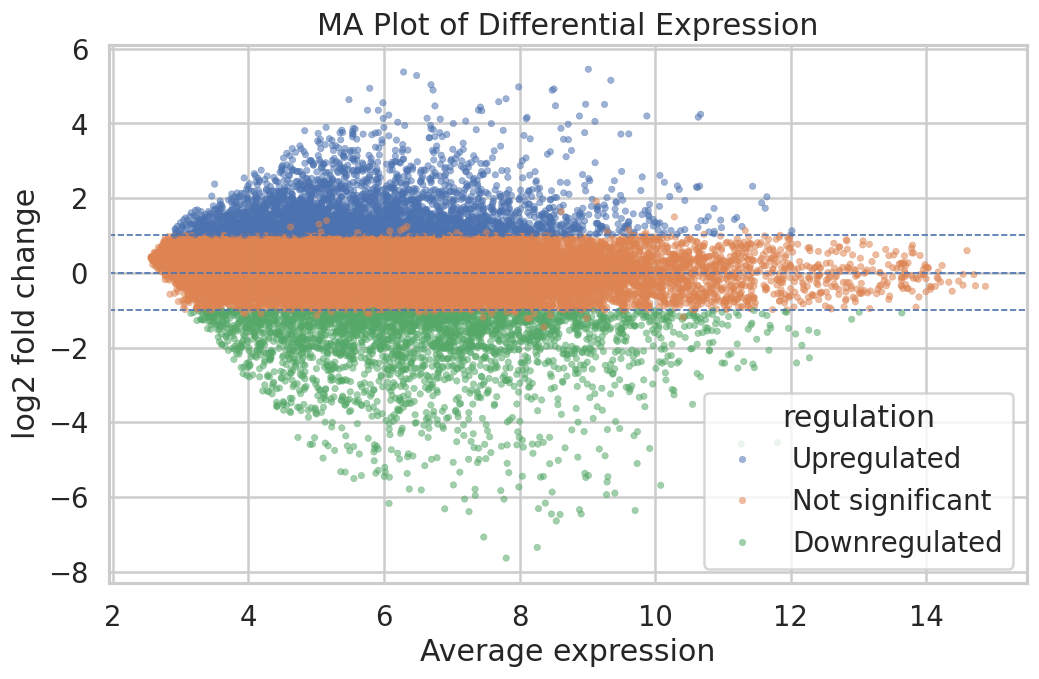

In [11]:
ma = deg.copy()
ma["average_expression"] = (ma["mean_tumor"] + ma["mean_normal"]) / 2

plt.figure(figsize=(9, 6))
sns.scatterplot(data=ma, x="average_expression", y="logFC", hue="regulation", alpha=0.55, s=15, edgecolor=None)
plt.axhline(-1, linestyle="--", linewidth=1)
plt.axhline(0, linestyle="--", linewidth=1)
plt.axhline(1, linestyle="--", linewidth=1)
plt.title("MA Plot of Differential Expression")
plt.xlabel("Average expression")
plt.ylabel("log2 fold change")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ma_plot_tumor_vs_normal.png", dpi=300)
plt.show()


## 9. Heatmap — Top 50 Differentially Expressed Probes

Z-score normalised expression values (per probe, across samples) for the 50 most significant
probes. Samples are ordered with all Normal samples first, then Tumor, to make the group
separation visually clear. Row labels show gene symbols where available, probe IDs otherwise.

A clear block structure (Normal vs Tumor) confirms the DE results reflect real biology rather
than technical noise.


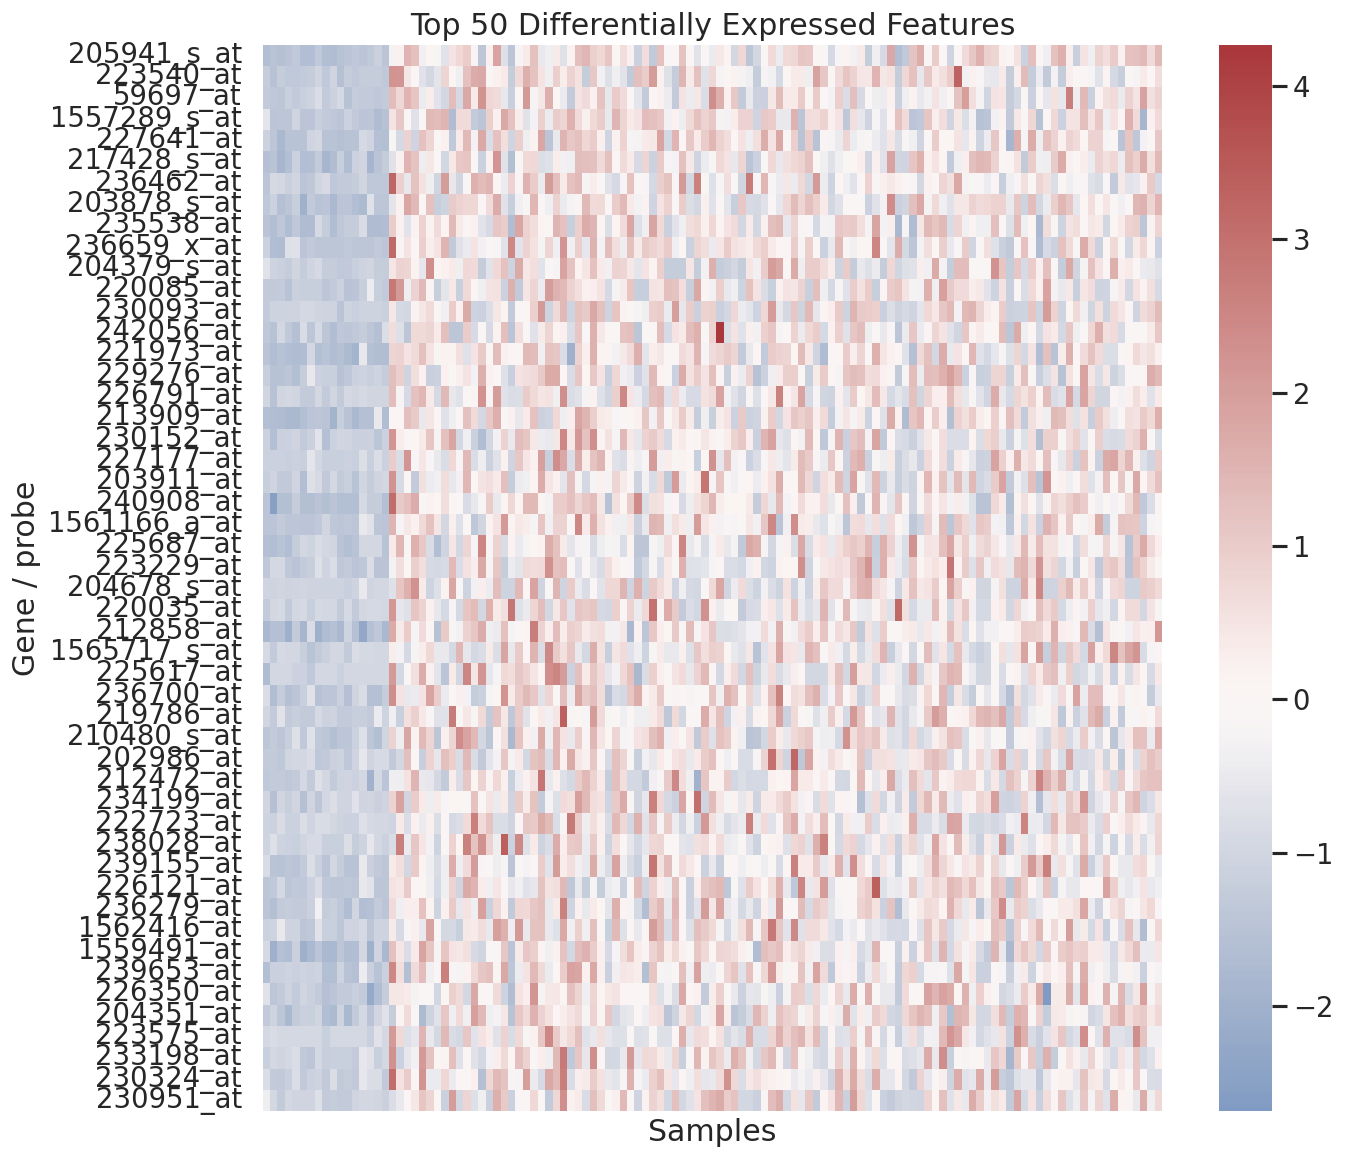

In [12]:
top_50 = deg.sort_values("adj_p_value").head(50)["probe_id"].tolist()
heatmap_expr = expr_norm.loc[top_50]

heatmap_z = heatmap_expr.sub(heatmap_expr.mean(axis=1), axis=0).div(heatmap_expr.std(axis=1), axis=0)
ordered_samples = classified.sort_values("group")["sample_id"].tolist()
heatmap_z = heatmap_z[ordered_samples]

label_lookup = {}
if "gene_symbol" in deg_annot.columns:
    label_lookup = deg_annot.dropna(subset=["gene_symbol"]).drop_duplicates("probe_id").set_index("probe_id")["gene_symbol"].to_dict()
row_labels = [label_lookup.get(pid, pid) for pid in heatmap_z.index]

plt.figure(figsize=(12, 10))
sns.heatmap(heatmap_z, cmap="vlag", center=0, xticklabels=False, yticklabels=row_labels)
plt.title("Top 50 Differentially Expressed Features")
plt.xlabel("Samples")
plt.ylabel("Gene / probe")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_50_deg_heatmap.png", dpi=300)
plt.show()


## 10. Gene Set Enrichment — Enrichr (Optional)

GO Biological Process enrichment is run on the upregulated and downregulated gene sets using
the Enrichr API via `gseapy`. This step requires an internet connection and annotated gene
symbols; it is wrapped in a try/except and skipped silently if either is unavailable.

Results are saved to CSV for further interpretation. Expected enriched terms for breast cancer
upregulated genes include cell cycle, DNA replication, and proliferation pathways.


In [13]:
try:
    import gseapy as gp

    if "gene_symbol" in deg_annot.columns:
        up_genes = deg_annot.query("regulation == 'Upregulated'")["gene_symbol"].dropna().astype(str).unique().tolist()
        down_genes = deg_annot.query("regulation == 'Downregulated'")["gene_symbol"].dropna().astype(str).unique().tolist()

        if len(up_genes) > 10:
            enr_up = gp.enrichr(gene_list=up_genes[:1000], gene_sets=["GO_Biological_Process_2023"], organism="Human", outdir=None)
            go_up = enr_up.results
            go_up.to_csv(OUTPUT_DIR / "go_enrichment_upregulated_genes_enrichr.csv", index=False)
            display(go_up.head(10))

        if len(down_genes) > 10:
            enr_down = gp.enrichr(gene_list=down_genes[:1000], gene_sets=["GO_Biological_Process_2023"], organism="Human", outdir=None)
            go_down = enr_down.results
            go_down.to_csv(OUTPUT_DIR / "go_enrichment_downregulated_genes_enrichr.csv", index=False)
            display(go_down.head(10))
except Exception as e:
    print("Optional Enrichr analysis skipped or failed:", e)


Optional Enrichr analysis skipped or failed: No module named 'gseapy'


## 11. Final Analysis Summary

Key statistics from the complete run, saved to `outputs/analysis_summary.txt` for reference
and reproducibility reporting.


In [14]:
summary_lines = [
    f"Dataset: {GSE_ID}",
    f"Number of samples: {expr_norm.shape[1]}",
    f"Normal samples: {(classified['group'] == 'Normal').sum()}",
    f"Tumor samples: {(classified['group'] == 'Tumor').sum()}",
    f"Probes after IQR filter: {expr_norm.shape[0]:,}",
    f"Probes tested: {len(deg):,}",
    f"Significant (FDR < 0.05): {(deg['adj_p_value'] < 0.05).sum():,}",
    f"Upregulated (FDR<0.05, logFC>=1): {(deg['regulation']=='Upregulated').sum():,}",
    f"Downregulated (FDR<0.05, logFC<=-1): {(deg['regulation']=='Downregulated').sum():,}",
]

summary_text = "\n".join(summary_lines)
print(summary_text)

with open(OUTPUT_DIR / "analysis_summary.txt", "w") as f:
    f.write(summary_text)


Dataset: GSE42568
Number of samples: 121
Normal samples: 17
Tumor samples: 104
Probes after IQR filter: 22,426
Probes tested: 22,426
Significant (FDR < 0.05): 13,893
Upregulated (FDR<0.05, logFC>=1): 3,420
Downregulated (FDR<0.05, logFC<=-1): 2,615
